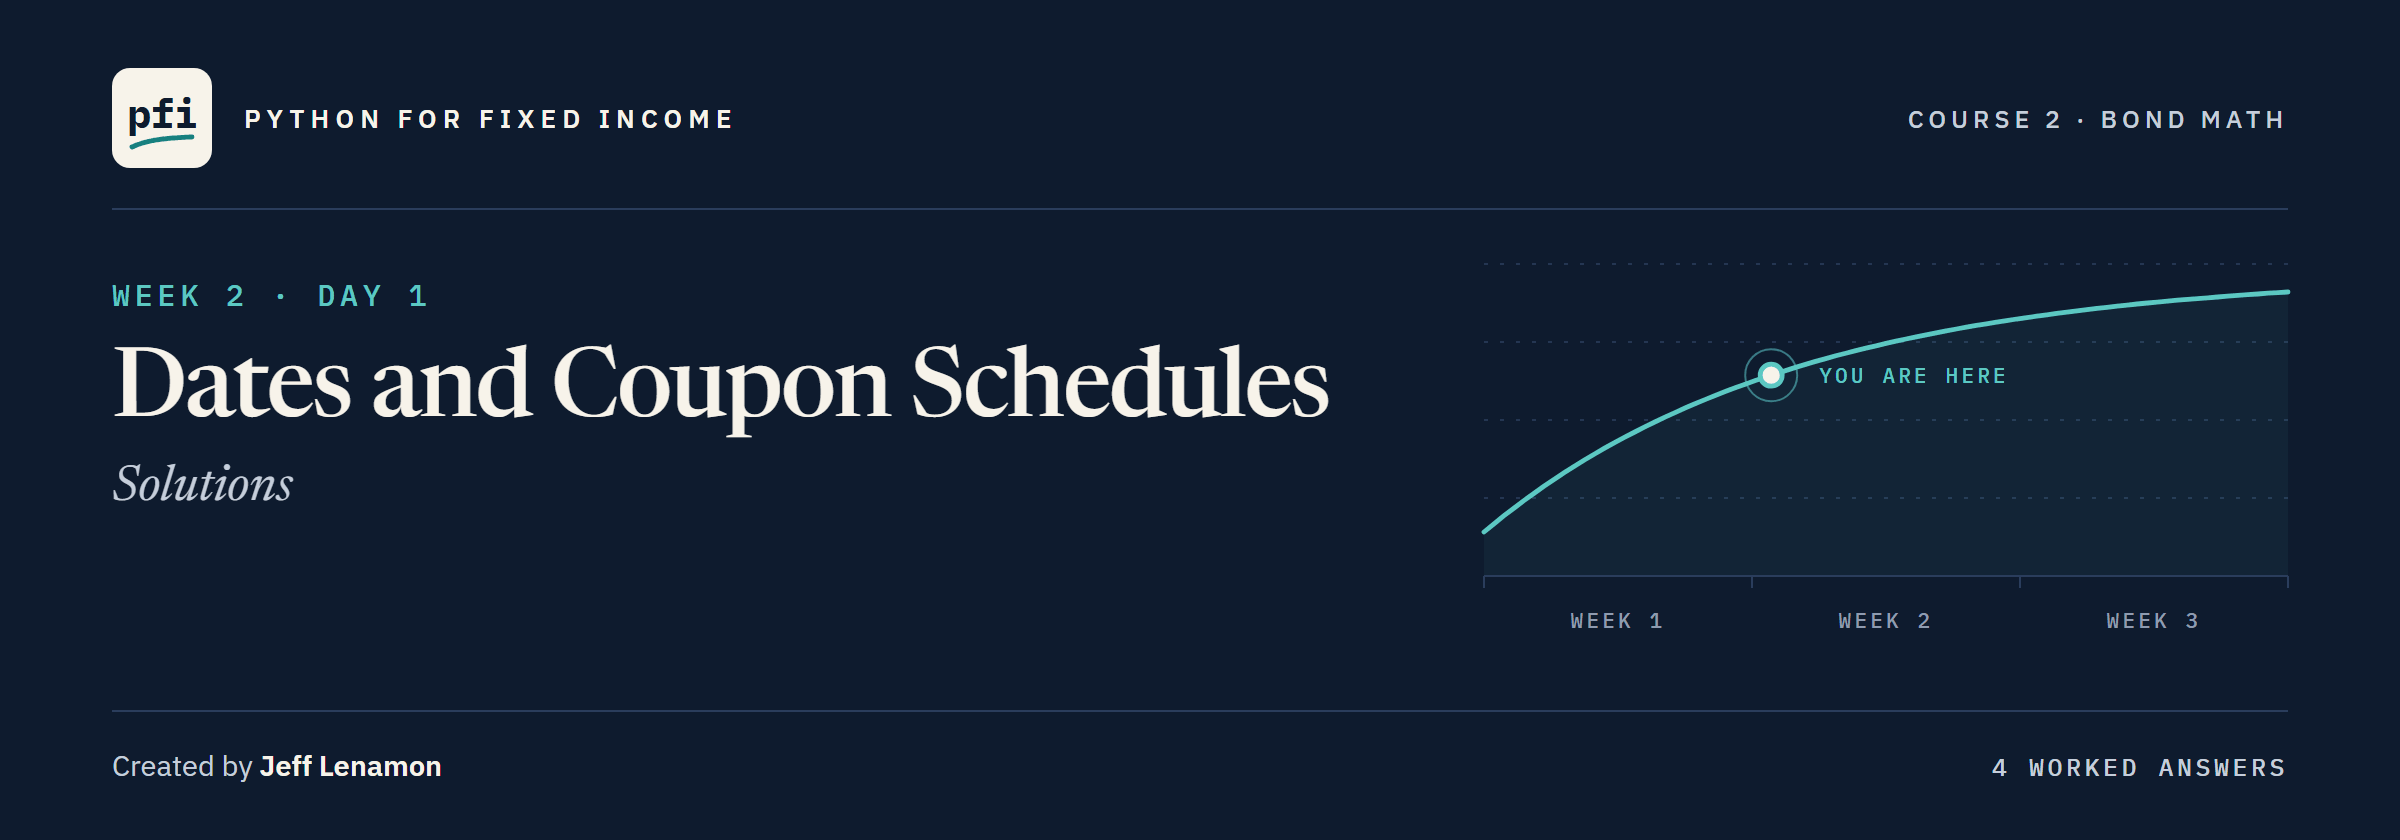

# Dates and Coupon Schedules: Solutions

Week 2, Day 1. Worked answers to the exercises. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week2/day1/06_dates_and_coupon_schedules_solutions.ipynb)

## Exercises

Run the next cells first: the work folder with the module as this notebook leaves it, the imports, `check`, and the second set of bonds.

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/course02_bond_math/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}start_of_day/start_day.py
from start_day import start_day

# a new work folder: the Excel files, and the module and its tests as notebook 06 ends.
# To start the day again, restart the kernel and run all cells.
work = start_day(6, after=6)

Work folder pfi_course2_06_k4w7q2xr: 4 data files, the module as notebook 06 left it, 6 commits, tagged week1


In [2]:
import calendar
import importlib
from datetime import date

import pandas as pd

import bondmath
print(bondmath.coupon_dates(date(2026, 11, 30), date(2031, 9, 30))[1])

2027-03-31


In [3]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [4]:
exercise_bonds = pd.DataFrame({
    'ticker': ['OSTV', 'TRNW', 'OSMC', 'CLDB'],
    'issuer': ['Ostrevale Telecom', 'Tarnwick Utilities', 'Osmere Chemicals', 'Calderby Retail'],
    'maturity': ['2030-09-30', '2028-09-30', '2032-09-30', '2034-09-30'],
})
exercise_bonds['maturity_date'] = [date.fromisoformat(t) for t in exercise_bonds['maturity']]
settlement = date(2026, 11, 30)
exercise_bonds

,ticker,issuer,maturity,maturity_date
0,OSTV,Ostrevale Telecom,2030-09-30,2030-09-30
1,TRNW,Tarnwick Utilities,2028-09-30,2028-09-30
2,OSMC,Osmere Chemicals,2032-09-30,2032-09-30
3,CLDB,Calderby Retail,2034-09-30,2034-09-30


### Exercise 1

In [5]:
# one list of coupon dates per bond, as in 6.6
ex_dates = [bondmath.coupon_dates(settlement, m) for m in exercise_bonds['maturity_date']]
exercise_bonds['previous'] = [d[0] for d in ex_dates]
exercise_bonds['next'] = [d[1] for d in ex_dates]
exercise_bonds['left'] = [len(d) - 1 for d in ex_dates]
print(exercise_bonds[['ticker', 'previous', 'next', 'left']])
ex1_next = exercise_bonds.loc[exercise_bonds['ticker'] == 'CLDB', 'next'].iloc[0]
ex1_total = exercise_bonds['left'].sum()

  ticker    previous        next  left
0   OSTV  2026-09-30  2027-03-31     8
1   TRNW  2026-09-30  2027-03-31     4
2   OSMC  2026-09-30  2027-03-31    12
3   CLDB  2026-09-30  2027-03-31    16


All four share 30 September 2026 and 31 March 2027: each matures on 30 September, a month end.

In [6]:
check('Exercise 1 Calderby next coupon', ex1_next, date(2027, 3, 31))
check('Exercise 1 coupons left, all four', ex1_total, 40)

Exercise 1 Calderby next coupon: correct
Exercise 1 coupons left, all four: correct


### Exercise 2

In [7]:
# Calderby's dates, then each date paired with the next, as in 6.6
calderby_dates = bondmath.coupon_dates(settlement, date(2034, 9, 30))
lengths = [(later - earlier).days
           for earlier, later in zip(calderby_dates, calderby_dates[1:])]
print(lengths)
ex2_shortest, ex2_longest = min(lengths), max(lengths)
ex2_count_183 = len([n for n in lengths if n == 183])

[182, 183, 183, 183, 182, 183, 182, 183, 182, 183, 183, 183, 182, 183, 182, 183]


31 March to 30 September is always 183 days; 30 September to 31 March is 182, or 183 when it holds a 29 February.

In [8]:
check('Exercise 2 shortest period', ex2_shortest, 182)
check('Exercise 2 longest period', ex2_longest, 183)
check('Exercise 2 periods of 183 days', ex2_count_183, 10)

Exercise 2 shortest period: correct
Exercise 2 longest period: correct
Exercise 2 periods of 183 days: correct


### Exercise 3

In [9]:
%%writefile -a bondmath.py


def coupons_remaining(settlement: date, maturity: date, frequency: int = 2) -> int:
    """The number of coupons still to be paid after settlement, through maturity.

    Units: dates in, a whole number out. Convention: the schedule of coupon_dates, so a coupon
    paid on the settlement date itself is not counted. Excel: =COUPNUM(settlement, maturity, frequency, 0)
    """
    # coupon_dates starts with the previous coupon, which is already paid
    return len(coupon_dates(settlement, maturity, frequency)) - 1

Appending to bondmath.py


In [10]:
%%writefile -a test_bondmath.py


def test_coupons_remaining_matches_excel_coupnum():
    # by hand: settled 30 November 2026, a 30 September 2028 maturity has 4 coupons left
    assert bondmath.coupons_remaining(date(2026, 11, 30), date(2028, 9, 30)) == 4
    # Excel's COUPNUM on every row of the reference file
    for row in REFERENCE:
        settlement, maturity = date.fromisoformat(row["settlement"]), date.fromisoformat(row["maturity"])
        result = bondmath.coupons_remaining(settlement, maturity, int(row["frequency"]))
        assert result == int(row["coupnum"]), row["case_id"]

Appending to test_bondmath.py


In [11]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

................                                                         [100%]
16 passed in 0.50s



In [12]:
# the file changed, so read it again before calling the new function
importlib.reload(bondmath)
ex3_tarnwick = bondmath.coupons_remaining(settlement, date(2028, 9, 30))
print('Tarnwick coupons left:', ex3_tarnwick)

Tarnwick coupons left: 4


31 March and 30 September in 2027 and 2028; `=COUPNUM(DATE(2026,11,30),DATE(2028,9,30),2,0)` returns 4.

In [13]:
check('Exercise 3 Tarnwick coupons left', ex3_tarnwick, 4)

Exercise 3 Tarnwick coupons left: correct


### Exercise 4: AI check

The code steps each date from the one before, `add_months(dates[-1], -step_months)`.
It keeps the month-end rule, so Quorvane came back right, but a 29th or 30th maturity drifts: once February cuts the day to the 28th, every earlier date keeps the 28th.
The test stopped on `edge_mat_29_aug`, and only 6 of the 306 rows fail.

The fix: count from maturity, as the docstring says.

`dates` holds every date found so far, so `len(dates)` steps back from maturity is the next one.

In [14]:
def assistant_coupon_dates(settlement, maturity, frequency=2):
    """The previous coupon date, then every coupon date left through maturity.

    Units: dates. Convention: coupon dates are counted back from maturity in steps of
    12 / frequency months, each one computed from maturity directly, so a 31st never drifts
    to the 28th. If maturity is the last day of its month, every coupon date is the last day
    of its month (Excel's rule). The previous coupon date is the last one on or before
    settlement. So [0] is Excel's COUPPCD, [1] is COUPNCD, and len - 1 is COUPNUM.
    """
    if frequency not in (1, 2, 4):
        raise ValueError(f'frequency must be 1, 2, or 4, not {frequency}')
    if settlement >= maturity:
        raise ValueError(f'settlement {settlement} must be before maturity {maturity}')
    step_months = 12 // frequency
    month_end = maturity.day == calendar.monthrange(maturity.year, maturity.month)[1]
    dates = [maturity]
    while dates[-1] > settlement:
        # the fix: count from maturity itself, len(dates) steps back
        coupon_date = bondmath.add_months(maturity, -len(dates) * step_months)
        if month_end:
            last_day = calendar.monthrange(coupon_date.year, coupon_date.month)[1]
            coupon_date = date(coupon_date.year, coupon_date.month, last_day)
        dates.append(coupon_date)
    dates.reverse()
    return dates

In [15]:
rows = pd.read_csv('bondmath_excel_reference.csv')
for case, s, m, f, previous, coming in zip(rows['case_id'], rows['settlement'], rows['maturity'],
                                           rows['frequency'], rows['couppcd'], rows['coupncd']):
    dates = assistant_coupon_dates(date.fromisoformat(s), date.fromisoformat(m), f)
    assert dates[0].isoformat() == previous, f'{case}: previous {dates[0]}, COUPPCD {previous}'
    assert dates[1].isoformat() == coming, f'{case}: next {dates[1]}, COUPNCD {coming}'
print(f'All {len(rows)} rows match COUPPCD and COUPNCD')
ex4_aug29_previous = assistant_coupon_dates(settlement, date(2031, 8, 29))[0]
ex4_aug30_previous = assistant_coupon_dates(settlement, date(2031, 8, 30))[0]

All 306 rows match COUPPCD and COUPNCD


Quorvane's check passed before the fix: a test of one bond on a month end could not have caught a drift that needs a 29th or 30th.

In [16]:
check('Exercise 4 previous coupon, 29 August maturity', ex4_aug29_previous, date(2026, 8, 29))
check('Exercise 4 previous coupon, 30 August maturity', ex4_aug30_previous, date(2026, 8, 30))

Exercise 4 previous coupon, 29 August maturity: correct
Exercise 4 previous coupon, 30 August maturity: correct


[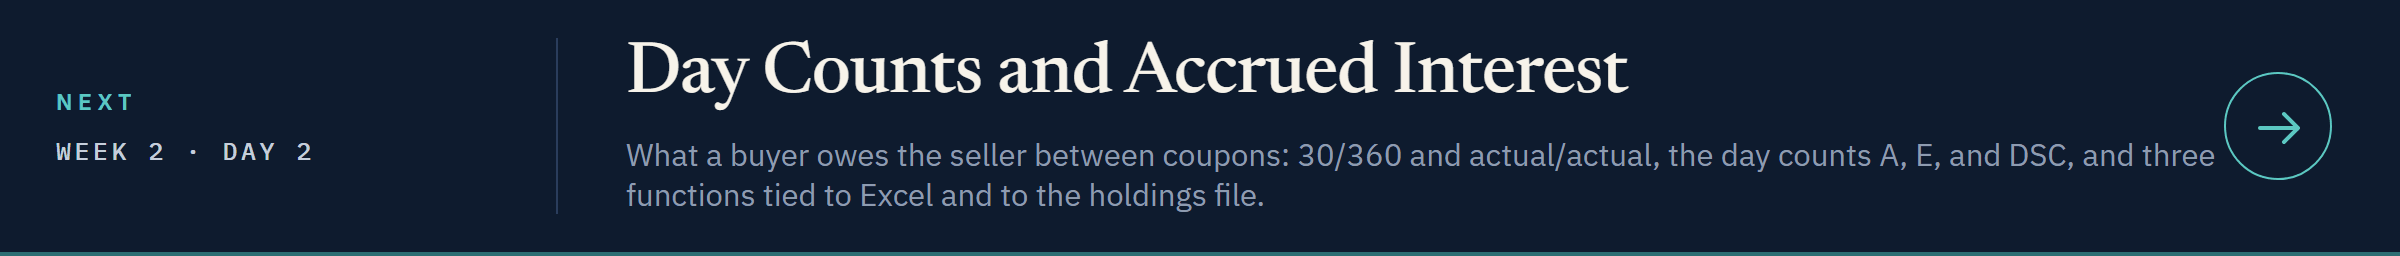](../day2/07_day_counts_and_accrued_interest.ipynb)

[Open Day 2 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week2/day2/07_day_counts_and_accrued_interest.ipynb)